# TV3 — Tuần 2: Tài Liệu & Biểu Đồ Hỗ Trợ Soạn Slide Báo Cáo (5 Phút)

Notebook này tổng hợp trọn bộ **nội dung phân tích** và **các biểu đồ chuẩn trình chiếu (250 DPI, chữ lớn)** được chia theo đúng bố cục **3 Slide** cho buổi báo cáo 5 phút với giảng viên:
- **Slide 1**: Biểu đồ `Training Loss` của **Lần chạy 1 (`outputs_1st`)** + Phân tích hiện tượng tách nhóm & nghịch lý điểm `Validation Dice`.
- **Slide 2**: Phân tích **3 Nguyên nhân gốc rễ** kèm biểu đồ **bằng chứng định lượng** trích xuất trực tiếp từ trọng số checkpoint thật.
- **Slide 3**: Biểu đồ `Training Loss` của **Lần chạy 3 (`outputs_latest`)** + Bảng đối chiếu **12 con số** (`Lần 1` $\rightarrow$ `Lần 3`) & giải thích thực trạng hiện tại.

> **Hướng dẫn cho người làm slide:** Mỗi phần bên dưới gồm 1 ô Markdown giải thích chi tiết ý cần truyền đạt và 1 ô Code xuất sẵn hình ảnh + bảng số liệu. Bạn chỉ cần chắt lọc các ý in đậm để đưa lên slide và lưu các biểu đồ ngay bên dưới để chèn trực tiếp.

---
## SLIDE 1: Kết Quả Lần Chạy 1 (`outputs_1st`) — Bất Thường Giữa Tốc Độ Hội Tụ Và Chất Lượng Cuối

### Bố cục gợi ý cho Slide 1
- **Bên trái (~60%):** Chèn biểu đồ `Training Loss` phóng to ở ô code ngay bên dưới.
- **Bên phải (~40%):** Trình bày ngắn gọn **2 luận điểm (bullets)** kèm bảng **6 con số Validation Dice Score**.

### Nội dung chi tiết cho 2 Luận điểm

1. **Xu hướng tách nhóm trên Training Loss & Giải mã cơ chế của FiLM:**
   - **Quan sát trực quan:** Các đường `IP1`, `IP2`, `IP3` có cùng chế độ FiLM tự động nhập cụm với nhau, tạo thành **2 nhóm tách biệt hoàn toàn** trong 15 epoch đầu: **3 đường nét liền (`With FiLM`) lao dốc nhanh hơn hẳn** so với **3 đường nét đứt (`No FiLM`)** (chỉ mất ~6–8 epochs để xuống mức Loss `0.50`, nhanh gấp đôi `No FiLM`).
   - **FiLM gắn vào U-Net như thế nào?** FiLM là nhánh phụ nhận vector phân nhóm sinh học khối u (4 lớp), sinh ra 2 tham số điều chế là hệ số nhân **scale ($\gamma$)** và độ dịch **shift ($\beta$)** gắn vào **7 tầng sâu** của mạng 3D Attention U-Net (2 tầng cuối Encoder, Bottleneck, và 4 tầng Decoder) theo công thức:
     $$\tilde{F} = (1 + \gamma) \cdot F + \beta$$
   - **Giải thích câu hỏi: Công thức trông giống $y = ax + b$ như các lớp tích chập thường, vậy tại sao lại hội tụ nhanh hơn?**
     - Trong U-Net thường (`No FiLM`), mỗi bộ lọc `Conv3d` cũng có dạng tuyến tính, nhưng chỉ tác động cục bộ trên từng vùng nhỏ $3\times 3\times 3$, và ở lớp đầu ra cuối cùng chỉ có **duy nhất 1 tham số vô hướng `out_head.bias`** để chỉnh độ lệch chung cho toàn ảnh.
     - Ngược lại, **Multi-Stage FiLM tạo ra một "đường cao tốc tuyến tính" gồm 128 chiều nối thẳng vào hàng trăm kênh đặc trưng ở sát tầng ra**. Vì khối u thực tế rất nhỏ (nền chiếm đại đa số), FiLM có thể dễ dàng cộng ngay một độ lệch âm khổng lồ bằng $\beta$ trên toàn bộ bản đồ đặc trưng để ép Loss giảm cấp tốc trong vài epoch đầu, thay vì phải học từ từ qua các lớp tích chập 3D.

2. **Nghịch lý ở kết quả cuối cùng (Validation Dice Score):**
   - Trái ngược với tốc độ giảm Loss vượt trội ở giai đoạn đầu, **càng về cuối cả 3 cấu hình `With FiLM` đều có điểm Validation Dice tốt nhất thấp hơn `No FiLM`** (thua từ `-0.23%` đến `-0.54%`, riêng `run12` đạt đỉnh sớm tại Epoch 32 rồi dừng sớm ở Epoch 57):
     - `IP1 (Post-1)`: `No FiLM` = **0.8520** vs `With FiLM` = **0.8497** (`-0.23%`)
     - `IP2 (Subtraction)`: `No FiLM` = **0.8378** vs `With FiLM` = **0.8353** (`-0.25%`)
     - `IP3 (Multi-Channel)`: `No FiLM` = **0.8535** vs `With FiLM` = **0.8481** (`-0.54%`)

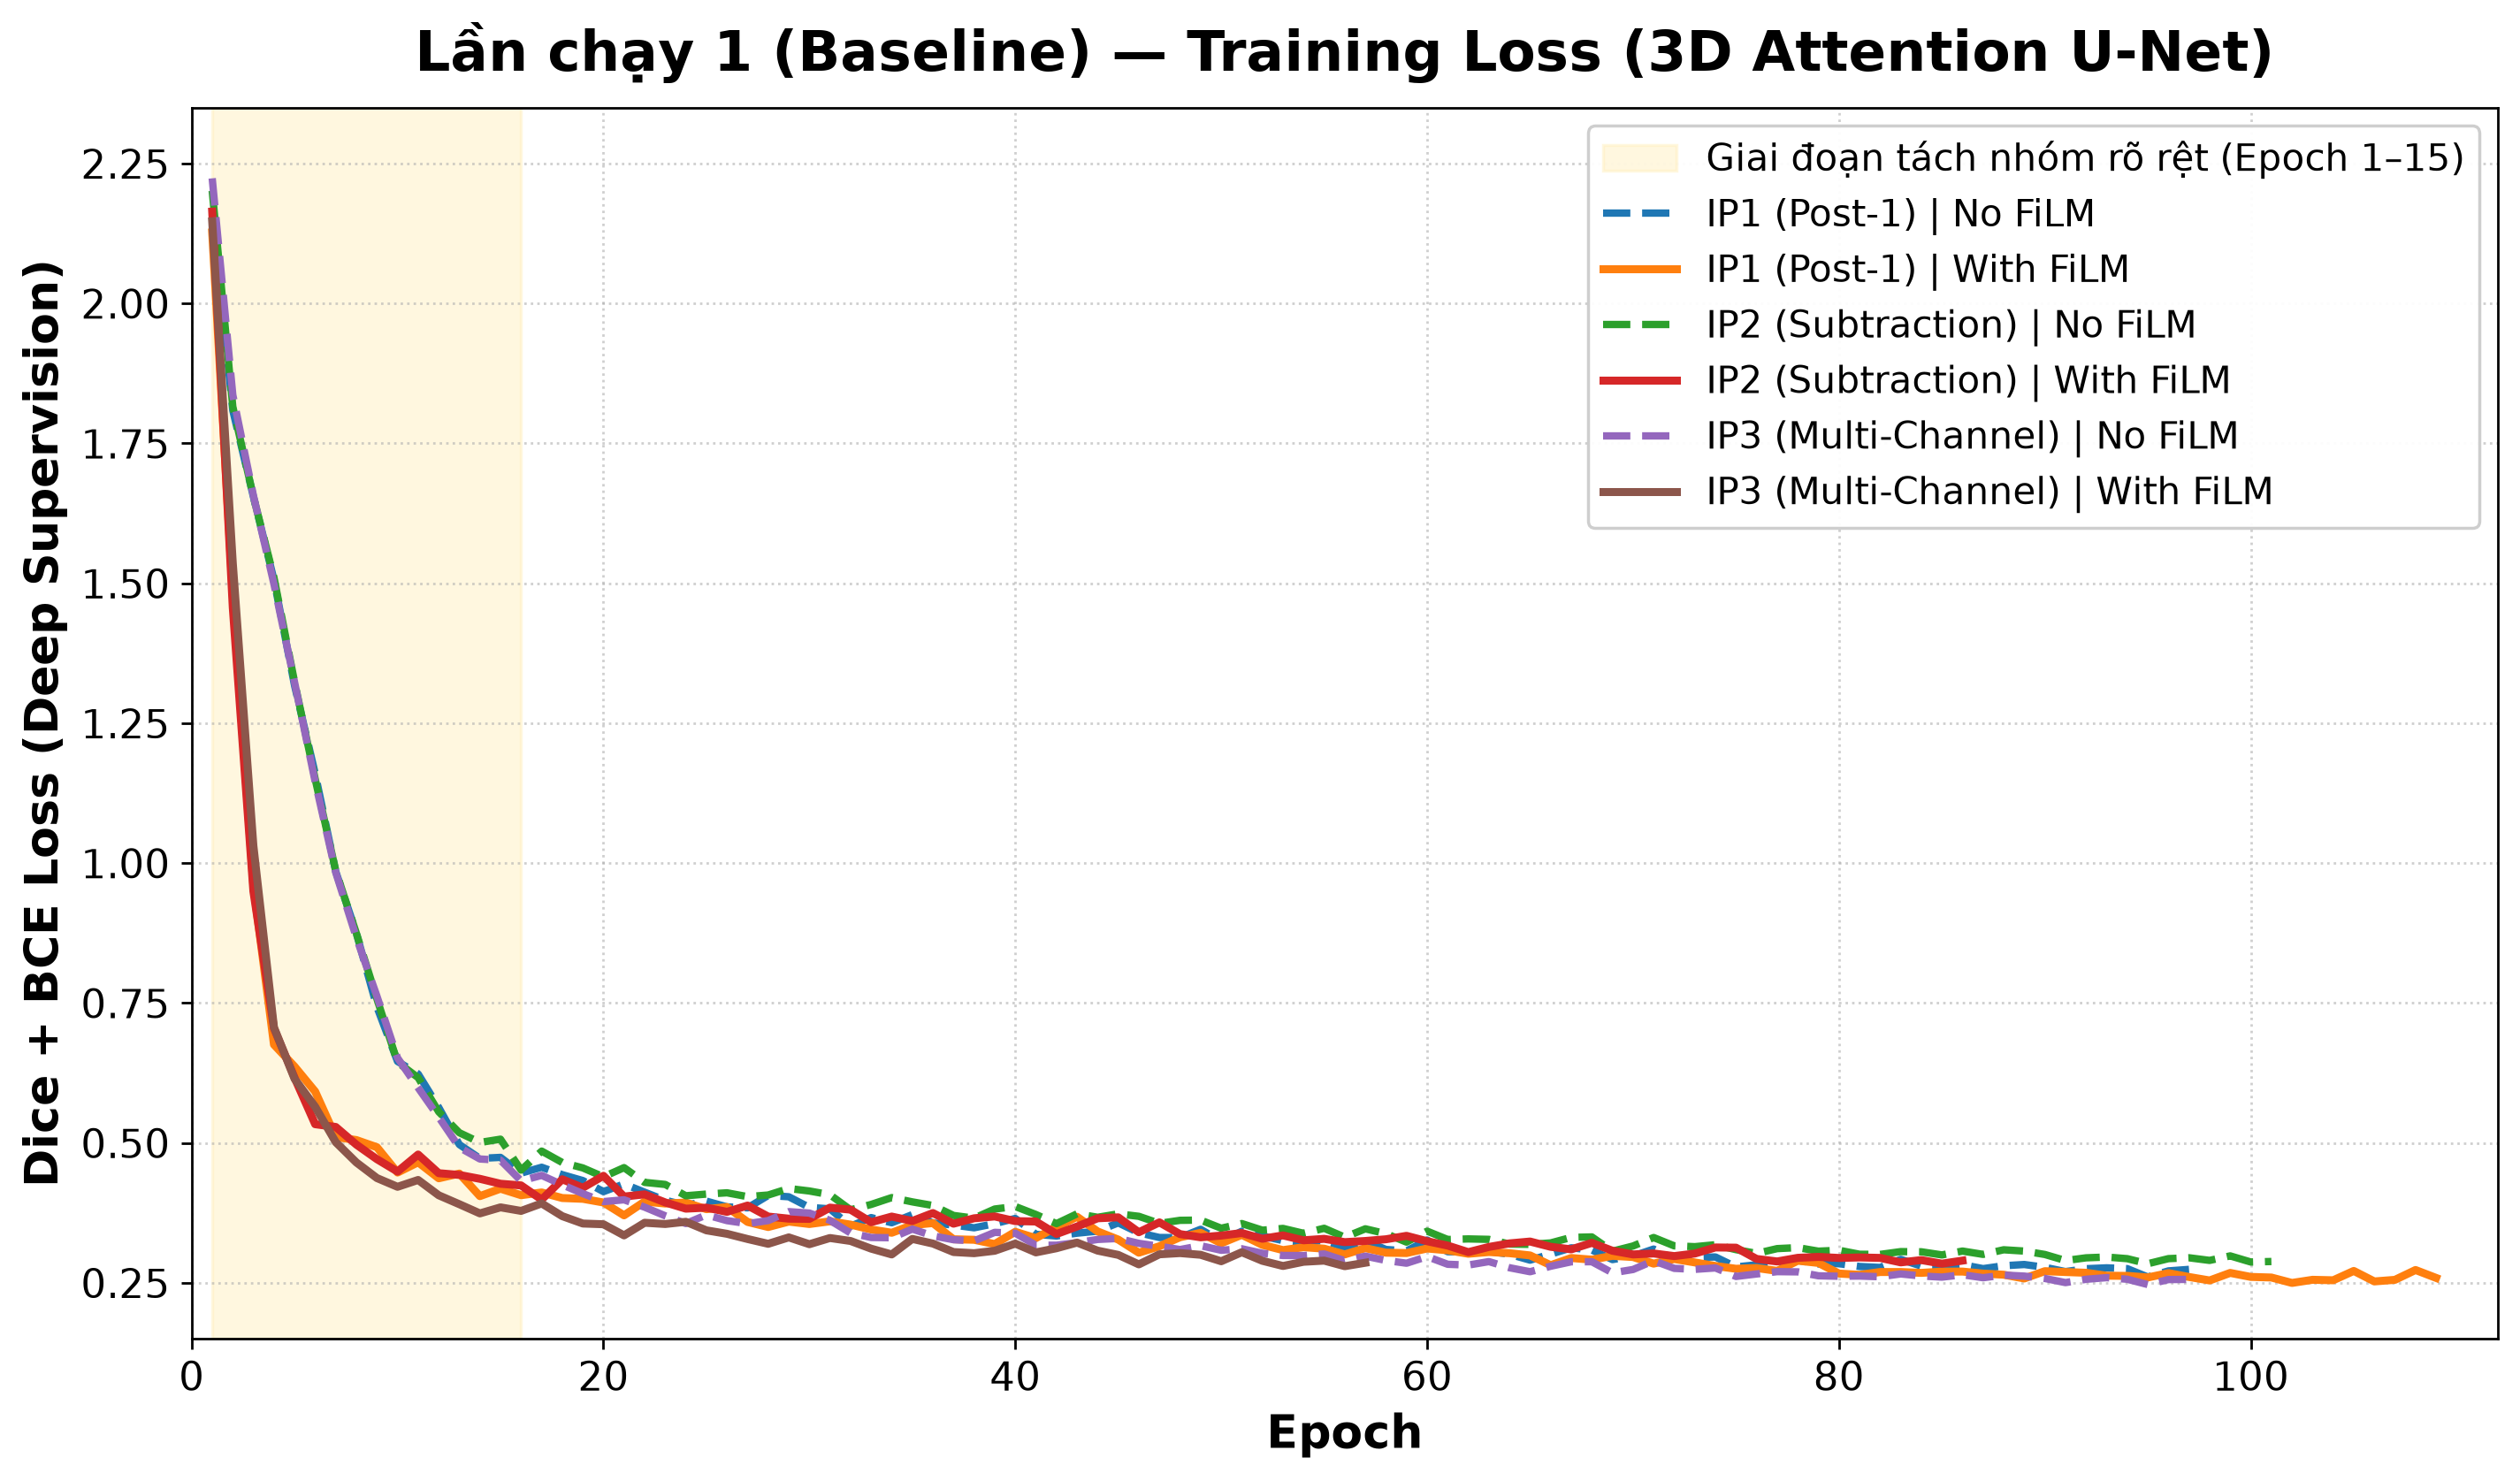

=== BẢNG 6 CON SỐ VALIDATION DICE SCORE — LẦN CHẠY 1 ===
run_id   ip_mode  use_film  best_epoch  epochs_trained best_val_dice
 run07 IP1_post1     False          72              97        0.8520
 run08 IP1_post1      True          84             109        0.8497
 run09   IP2_sub     False          76             101        0.8378
 run10   IP2_sub      True          61              86        0.8353
 run11 IP3_multi     False          72              97        0.8535
 run12 IP3_multi      True          32              57        0.8481


In [1]:
# =========================================================================
# SLIDE 1 FIGURE & TABLE: Standalone Large-Font Training Loss (Run 1)
# =========================================================================
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

WORKSPACE = Path("..") if Path("..").joinpath("outputs_1st").exists() else Path(".")
df1_hist = pd.read_csv(WORKSPACE / "outputs_1st" / "tables" / "tv3_week2_training_histories.csv")
df1_sum = pd.read_csv(WORKSPACE / "outputs_1st" / "tables" / "tv3_week2_ablation_summary.csv")

RUN_SPECS = [
    ("run07", "IP1 (Post-1) | No FiLM", False, "#1f77b4"),
    ("run08", "IP1 (Post-1) | With FiLM", True, "#ff7f0e"),
    ("run09", "IP2 (Subtraction) | No FiLM", False, "#2ca02c"),
    ("run10", "IP2 (Subtraction) | With FiLM", True, "#d62728"),
    ("run11", "IP3 (Multi-Channel) | No FiLM", False, "#9467bd"),
    ("run12", "IP3 (Multi-Channel) | With FiLM", True, "#8c564b"),
]

fig, ax = plt.subplots(figsize=(11.5, 6.8), dpi=250)
ax.axvspan(1, 16, color="#ffeeba", alpha=0.45, label="Giai đoạn tách nhóm rõ rệt (Epoch 1–15)")

for run_id, label, use_film, color in RUN_SPECS:
    sub = df1_hist[df1_hist["run_id"] == run_id].sort_values("epoch")
    ls = "-" if use_film else "--"
    lw = 2.6 if use_film else 2.4
    ax.plot(sub["epoch"], sub["train_loss"], linestyle=ls, linewidth=lw, color=color, label=label)

ax.set_title("Lần chạy 1 (Baseline) — Training Loss (3D Attention U-Net)", fontsize=18, fontweight="bold", pad=12)
ax.set_xlabel("Epoch", fontsize=15, fontweight="bold")
ax.set_ylabel("Dice + BCE Loss (Deep Supervision)", fontsize=15, fontweight="bold")
ax.set_ylim(0.15, 2.35)
ax.set_xlim(0, 112)
ax.tick_params(axis="both", labelsize=13)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right", fontsize=12, frameon=True, framealpha=0.95)

plt.tight_layout()
plt.show()

print("=== BẢNG 6 CON SỐ VALIDATION DICE SCORE — LẦN CHẠY 1 ===")
disp_1 = df1_sum[["run_id", "ip_mode", "use_film", "best_epoch", "epochs_trained", "best_val_dice"]].copy()
disp_1["best_val_dice"] = disp_1["best_val_dice"].map(lambda x: f"{x:.4f}")
print(disp_1.to_string(index=False))

---
## SLIDE 2: Phân Tích Nguyên Nhân Gốc Rễ (Tại Sao Lần 1 Tách Nhóm & Thua Về Cuối?)

### Nội dung chi tiết để đưa lên Slide 2
Từ hiện tượng ở Slide 1, kiểm định trực tiếp kiến trúc và trọng số mô hình (`best.pt`) chỉ ra **3 nguyên nhân kỹ thuật liên hoàn**:

1. **Nguyên nhân 1 — "Bẫy Đường Tắt Dịch Nền Toàn Cục" (Global Bias Shortcut):**
   - **Bối cảnh mất cân bằng voxel:** Trong khối MRI $96\times 96\times 96$, khối u thực tế chỉ chiếm trung bình **~1.8% thể tích**, **98.2%** còn lại là nền đen và mô lành.
   - **Áp lực khởi tạo:** Lớp đầu ra mặc định khởi tạo `out_head.bias = 0.0` (tức đoán 50% mọi voxel đều là u), đẩy `Train Loss` khởi điểm lên **~2.22**.
   - **Cơ chế ăn gian:** Nhánh FiLM với 128 chiều tuyến tính nối thẳng vào Decoder trở thành con đường ngắn nhất để hạ Loss: nó đẩy đồng loạt độ lệch nền $\beta$ xuống âm ở các tầng ra nhằm "dập" 98.2% vùng nền trong 10 epoch đầu.

2. **Nguyên nhân 2 — FiLM Không Ràng Buộc Tâm & Biên Độ $\rightarrow$ Suy Biến 4 Phân Nhóm:**
   - Vì mô hình FiLM cũ không ràng buộc tổng điều chế giữa 4 phân nhóm phải cân bằng quanh 0 và không kẹp biên độ, cả 4 vector đại diện cho 4 loại ung thư đều **đồng loạt chạy về một hướng giống hệt nhau** để phụ giúp việc dịch nền.
   - **Bằng chứng định lượng (trích xuất từ checkpoint `run12` Lần 1):** Độ tương đồng Cosine giữa các vector $\beta$ của 4 phân nhóm ở tầng cuối `dec0` lên tới **`+0.9996`** (giống nhau tới 99.96%), với biên độ rất lớn (`mean |γ| = 1.78`, `mean |β| = 1.48`). FiLM hoàn toàn mất khả năng phân biệt đặc trưng sinh học giữa các loại khối u.

3. **Nguyên nhân 3 — "Bỏ Đói" Mạng Tích Chập 3D (Gradient Starvation) & Dừng Sớm:**
   - Khi FiLM gánh phần việc giảm Loss quá nhanh ở đầu, tín hiệu gradient truyền về để rèn luyện các tầng tích chập không gian 3D bị suy yếu.
   - **Bằng chứng định lượng (trích xuất từ checkpoint Lần 1):** Chuẩn trọng số lớp đầu ra `||W_out||` của `run12 (With FiLM)` bị tụt xuống chỉ còn **`0.7919`** — chỉ bằng **một nửa** so với **`1.6093`** của `run11 (No FiLM)`. Hậu quả là bộ trích xuất đặc trưng không gian kém sắc nét hơn ở giai đoạn tinh chỉnh biên u, đồng thời việc dùng chung Learning Rate lớn khiến FiLM hội tụ gắt quá sớm và kích hoạt Early Stopping sớm (`run12` đạt đỉnh tại Epoch 32, dừng ở Epoch 57).

> **Lưu ý cho người làm slide:** Ô code ngay dưới xuất sẵn biểu đồ đối chiếu định lượng giữa Lần 1 và Lần 3 lấy trực tiếp từ checkpoint thật trên máy (không cần chạy thêm bất kỳ thực nghiệm training nào). Biểu đồ này chứng minh nguyên nhân một cách đanh thép trước giảng viên.

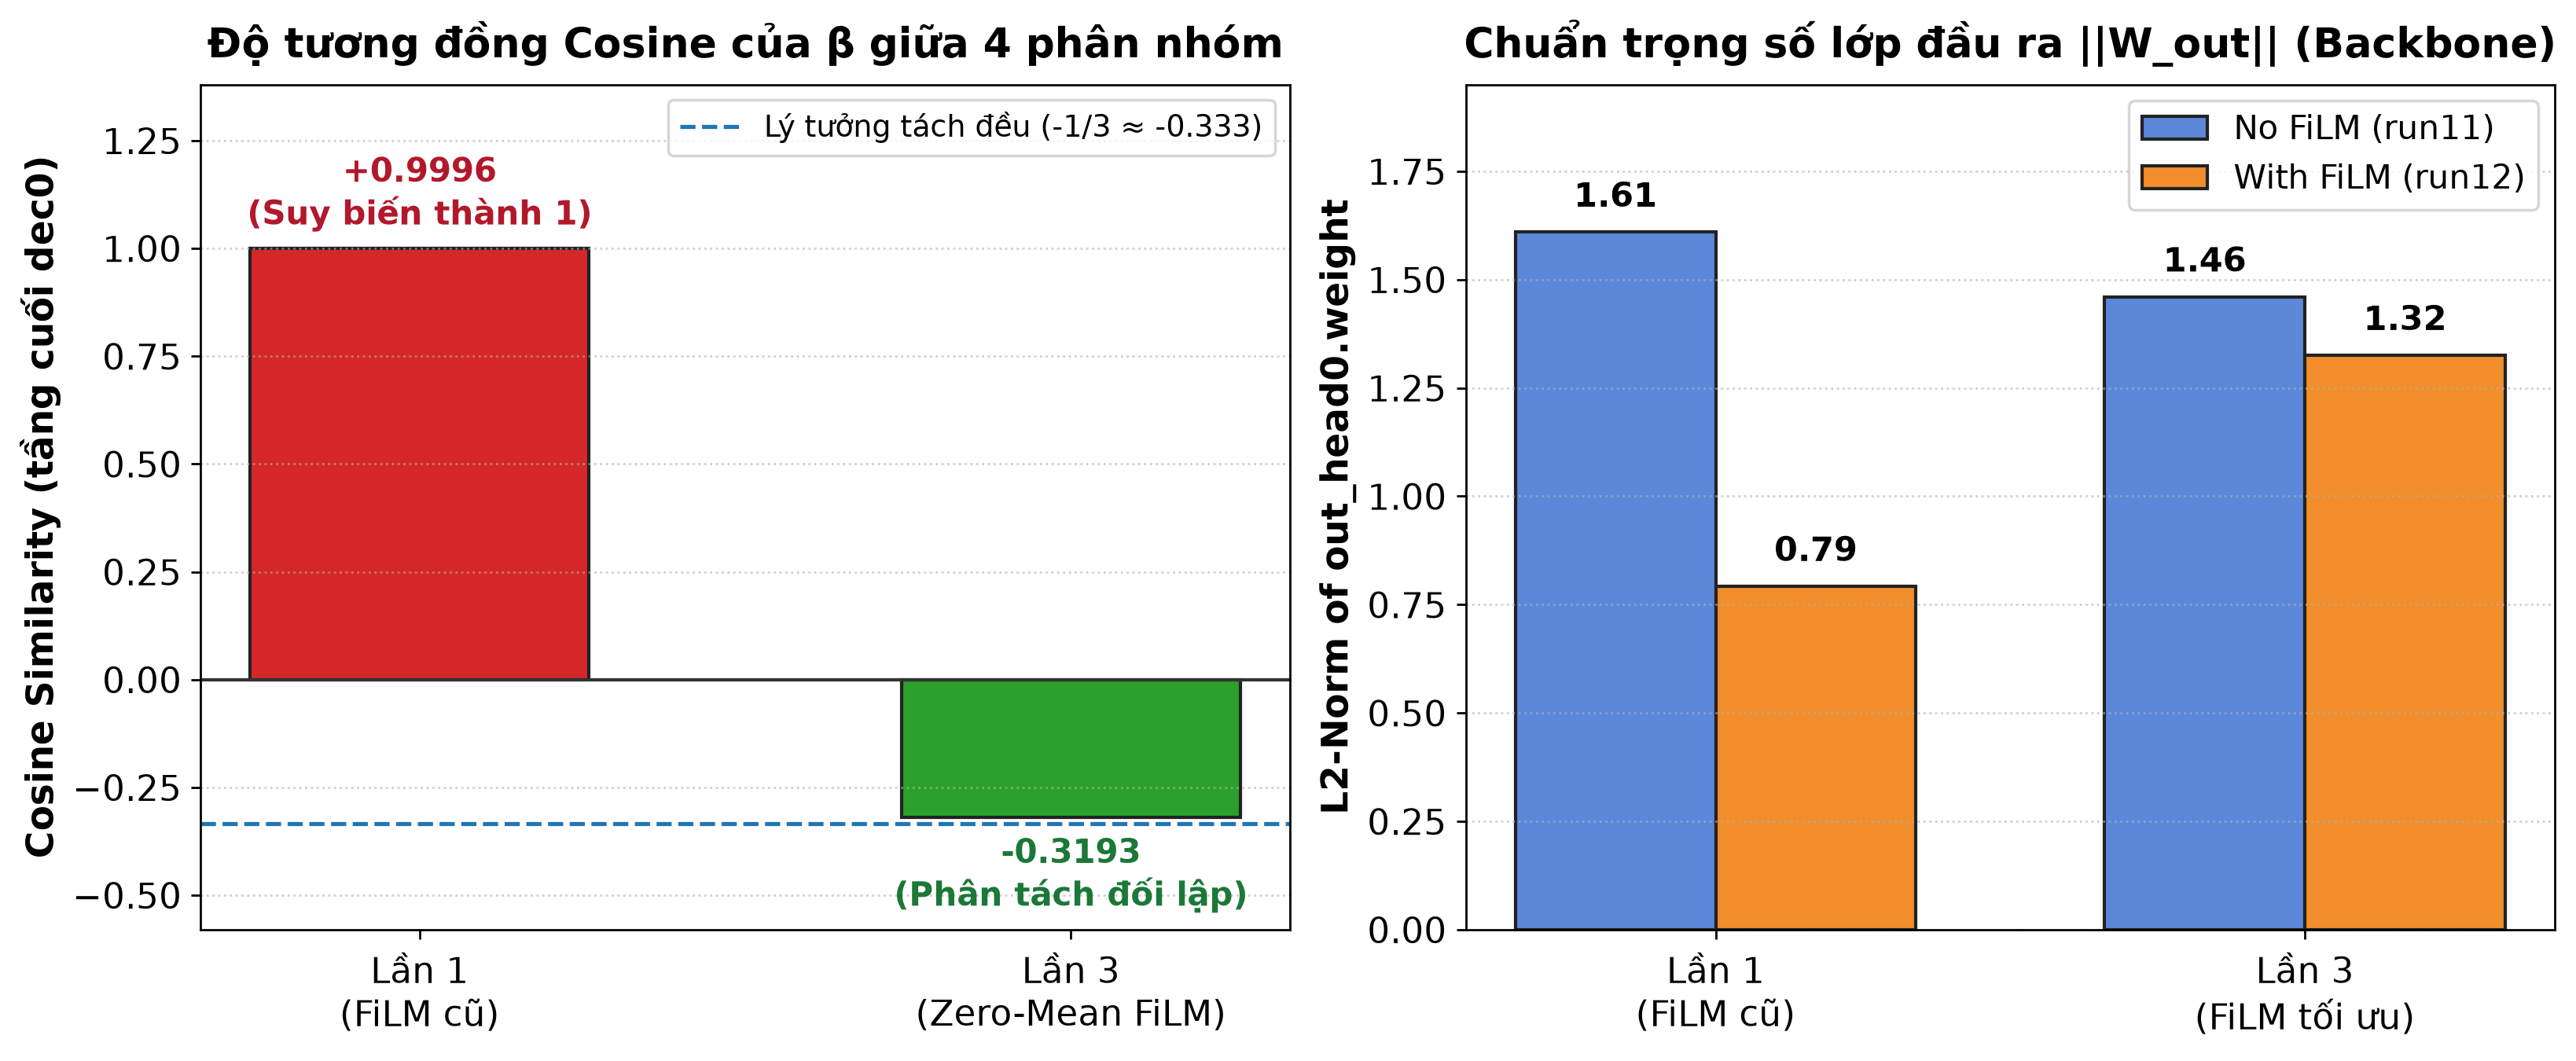

=== BẢNG THÔNG SỐ ĐỊNH LƯỢNG TRÍCH XUẤT TỪ CHECKPOINT THẬT ===
            label  cos_sim_beta  mean_abs_gamma  mean_abs_beta  w_out_no_film  w_out_with_film  bias_out_no_film  bias_out_with_film
 Lần 1 (Baseline)        0.9996          1.7784         1.4809         1.6093           0.7919           -0.2022             -0.0663
Lần 3 (Đã tối ưu)       -0.3193          0.0771         0.0447         1.4598           1.3248           -2.3697             -2.3714


In [2]:
# =========================================================================
# SLIDE 2 QUANTITATIVE EVIDENCE: Real Checkpoint Diagnostics (Run 1 vs Run 3)
# =========================================================================
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

WORKSPACE = Path("..") if Path("..").joinpath("outputs_1st").exists() else Path(".")

def inspect_run_pair(folder_name: str, is_latest: bool):
    ckpt_dir = WORKSPACE / folder_name / "checkpoints" / "tv3_week2"
    c11 = torch.load(ckpt_dir / "run11_M2_IP3_multi_no_film" / "best.pt", map_location="cpu", weights_only=True)["model"]
    c12 = torch.load(ckpt_dir / "run12_M2_IP3_multi_film" / "best.pt", map_location="cpu", weights_only=True)["model"]

    w11_norm = float(torch.norm(c11["out_head0.conv.conv.weight"]).item())
    w12_norm = float(torch.norm(c12["out_head0.conv.conv.weight"]).item())
    b11 = float(c11["out_head0.conv.conv.bias"].item())
    b12 = float(c12["out_head0.conv.conv.bias"].item())

    eye = torch.eye(4)
    h = F.silu(
        F.layer_norm(
            F.linear(eye, c12["film_generator.shared_mlp.0.weight"], c12["film_generator.shared_mlp.0.bias"]),
            (128,),
            c12["film_generator.shared_mlp.1.weight"],
            c12["film_generator.shared_mlp.1.bias"],
        )
    )
    if is_latest:
        h = h - h.mean(dim=0, keepdim=True)
    gb6 = F.linear(h, c12["film_generator.heads.6.weight"], c12["film_generator.heads.6.bias"])
    if is_latest:
        gb6 = gb6 - gb6.mean(dim=0, keepdim=True)
        gb6 = 0.25 * torch.tanh(gb6)
        gb6 = gb6 - gb6.mean(dim=0, keepdim=True)

    g6, b6 = gb6.chunk(2, dim=-1)
    cos_b6 = F.cosine_similarity(b6.unsqueeze(1), b6.unsqueeze(0), dim=-1)[~torch.eye(4, dtype=bool)]
    return {
        "label": "Lần 3 (Đã tối ưu)" if is_latest else "Lần 1 (Baseline)",
        "cos_sim_beta": float(cos_b6.mean().item()),
        "mean_abs_gamma": float(g6.abs().mean().item()),
        "mean_abs_beta": float(b6.abs().mean().item()),
        "w_out_no_film": w11_norm,
        "w_out_with_film": w12_norm,
        "bias_out_no_film": b11,
        "bias_out_with_film": b12,
    }

res_1st = inspect_run_pair("outputs_1st", is_latest=False)
res_3rd = inspect_run_pair("outputs_latest", is_latest=True)
df_diag = pd.DataFrame([res_1st, res_3rd])

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.5), dpi=250)

# Panel 1: Cosine similarity of dec0 shift vector beta across 4 subtypes
vals_cos = [res_1st["cos_sim_beta"], res_3rd["cos_sim_beta"]]
colors_cos = ["#d62728", "#2ca02c"]
bars1 = axes[0].bar(["Lần 1\n(FiLM cũ)", "Lần 3\n(Zero-Mean FiLM)"], vals_cos, color=colors_cos, width=0.52, edgecolor="#222222", linewidth=1.2)
axes[0].axhline(0.0, color="#333333", linewidth=1.2)
axes[0].axhline(-1/3, color="#1f77b4", linestyle="--", linewidth=1.5, label="Lý tưởng tách đều (-1/3 ≈ -0.333)")
axes[0].set_ylim(-0.58, 1.38)
axes[0].set_title("Độ tương đồng Cosine của β giữa 4 phân nhóm", fontsize=15, fontweight="bold", pad=10)
axes[0].set_ylabel("Cosine Similarity (tầng cuối dec0)", fontsize=13.5, fontweight="bold")
axes[0].tick_params(axis="both", labelsize=13)
axes[0].grid(axis="y", linestyle=":", alpha=0.6)
axes[0].legend(loc="upper right", fontsize=11)
axes[0].text(0, vals_cos[0] + 0.03, f"{vals_cos[0]:+.4f}\n(Suy biến thành 1)", ha="center", va="bottom", fontsize=12, fontweight="bold", color="#b2182b")
axes[0].text(1, vals_cos[1] - 0.04, f"{vals_cos[1]:+.4f}\n(Phân tách đối lập)", ha="center", va="top", fontsize=12, fontweight="bold", color="#1b7837")

# Panel 2: Output head weight L2-norm (Gradient starvation proof)
x = np.arange(2)
w = 0.34
no_film_norms = [res_1st["w_out_no_film"], res_3rd["w_out_no_film"]]
with_film_norms = [res_1st["w_out_with_film"], res_3rd["w_out_with_film"]]

b_no = axes[1].bar(x - w/2, no_film_norms, width=w, label="No FiLM (run11)", color="#5c88da", edgecolor="#222222", linewidth=1.2)
b_fi = axes[1].bar(x + w/2, with_film_norms, width=w, label="With FiLM (run12)", color="#f28e2b", edgecolor="#222222", linewidth=1.2)
axes[1].set_xticks(x, ["Lần 1\n(FiLM cũ)", "Lần 3\n(FiLM tối ưu)"], fontsize=13)
axes[1].set_ylim(0, 1.95)
axes[1].set_title("Chuẩn trọng số lớp đầu ra ||W_out|| (Backbone)", fontsize=15, fontweight="bold", pad=10)
axes[1].set_ylabel("L2-Norm of out_head0.weight", fontsize=13.5, fontweight="bold")
axes[1].tick_params(axis="y", labelsize=13)
axes[1].grid(axis="y", linestyle=":", alpha=0.6)
axes[1].legend(loc="upper right", fontsize=12)

for rect in list(b_no) + list(b_fi):
    h_val = rect.get_height()
    axes[1].text(rect.get_x() + rect.get_width()/2, h_val + 0.04, f"{h_val:.2f}", ha="center", va="bottom", fontsize=12.5, fontweight="bold")

plt.tight_layout()
plt.show()

print("=== BẢNG THÔNG SỐ ĐỊNH LƯỢNG TRÍCH XUẤT TỪ CHECKPOINT THẬT ===")
print(df_diag.round(4).to_string(index=False))

---
## SLIDE 3: Kết Quả Lần Chạy 3 (`outputs_latest`) — Khắc Phục Lỗi & Thực Trạng Hiện Tại

### Tóm tắt 3 sửa đổi kiến trúc/tối ưu ở Lần chạy 3 (khắc phục trực tiếp 3 nguyên nhân Slide 2)
1. **Khởi tạo tiên nghiệm `out_head.bias = -2.2`:** Đặt sẵn xác suất tiền cảnh ban đầu $\approx 10\%$ ngay từ Epoch 0 $\rightarrow$ Giải phóng toàn mạng khỏi áp lực dập nền (`Loss` Epoch 1 hạ từ `~2.22` xuống `~1.48`).
2. **Zero-Mean Subtype Centering + Bounded Tanh ($\pm 0.25$) + Dropout phân nhóm thực thụ ($p=0.15$):** Ép $\sum_{k=0}^{3} \gamma_k = 0, \sum_{k=0}^{3} \beta_k = 0$ để khóa 100% đường tắt dịch nền chung và giữ điều chế mượt mà.
3. **Tách Learning Rate (`Differential LR`):** Đặt tốc độ học của FiLM chậm hơn 3 lần (`lr_film = lr / 3`) so với Backbone 3D để FiLM không hội tụ quá gắt làm lấn át quá trình học đặc trưng không gian.

### Nội dung chi tiết cho 2 Luận điểm trên Slide 3

1. **6 đường Training Loss hợp nhất thành 1 cụm — Tín hiệu RẤT TỐT:**
   - **Hiện tượng:** Khác hẳn Lần 1 bị tách thành 2 cụm, ở Lần 3 **cả 6 đường Training Loss (cả `With FiLM` và `No FiLM`) nhập lại thành một bó mượt mà** ngay từ Epoch 1.
   - **Ý nghĩa:** Đây là bằng chứng trực quan chứng minh **bệnh "đường tắt dịch nền" đã được chữa dứt điểm**. Cả mô hình có FiLM và không FiLM đều xuất phát từ cùng một điểm cân bằng hình học và đều học biên khối u thực chất bằng các lớp tích chập 3D với nhịp độ lành mạnh như nhau.

2. **Đối chiếu 12 con số Validation Dice (Lần 1 $\rightarrow$ Lần 3) & Thực trạng hai nhóm xêm xêm nhau:**
   - **Chuyển biến tích cực:** Nhóm `With FiLM` đã **không còn thua** như ở Lần 1. Cấu hình tốt nhất `IP3 + FiLM` (`run12`) tăng mạnh từ `0.8481` $\rightarrow$ **`0.8533` (`+0.52%`)**, vươn lên đứng đầu cùng `IP3 No FiLM` (`0.8532`).
   - **Điểm hạn chế hiện tại — Tại sao giờ hai nhóm chỉ bằng nhau (`0.8533` vs `0.8532`), chưa vượt trội có ý nghĩa thống kê?**
     1. **Trần thông tin hình ảnh DCE-MRI (`IP3`):** Với bài toán khoanh vùng ranh giới khối u (nhị phân), bản thân 3 kênh ảnh tương phản động đầu vào đã cung cấp tín hiệu hình thái rất rõ để chạm ngưỡng ~`0.853`, nên việc biết thêm nhãn phân nhóm sinh học khó tạo ra cú nhảy vọt lớn về độ trùng khớp hình học tổng thể.
     2. **Hiệu ứng trung bình hóa trên tập Validation mất cân bằng:** Tập Val (177 ca) bị chi phối bởi nguồn `ISPY2` (~72% dữ liệu, chủ yếu là phân nhóm `Luminal` và có 0 ca `HER2-pure`). Khi gộp thành 1 điểm Dice trung bình toàn cục, lợi ích nếu có của FiLM trên các phân nhóm ít gặp hoặc đặc thù dễ bị san phẳng.
   - **Hướng tiếp theo (Next Steps):** Phân rã kết quả theo **từng phân nhóm sinh học (per-subtype Dice)**, chạy kiểm định chính thức trên **tập Test độc lập 300 ca**, và đối chiếu thêm với hai kiến trúc `3D ResUNet` (M1) và `3D Swin UNETR` (M3).

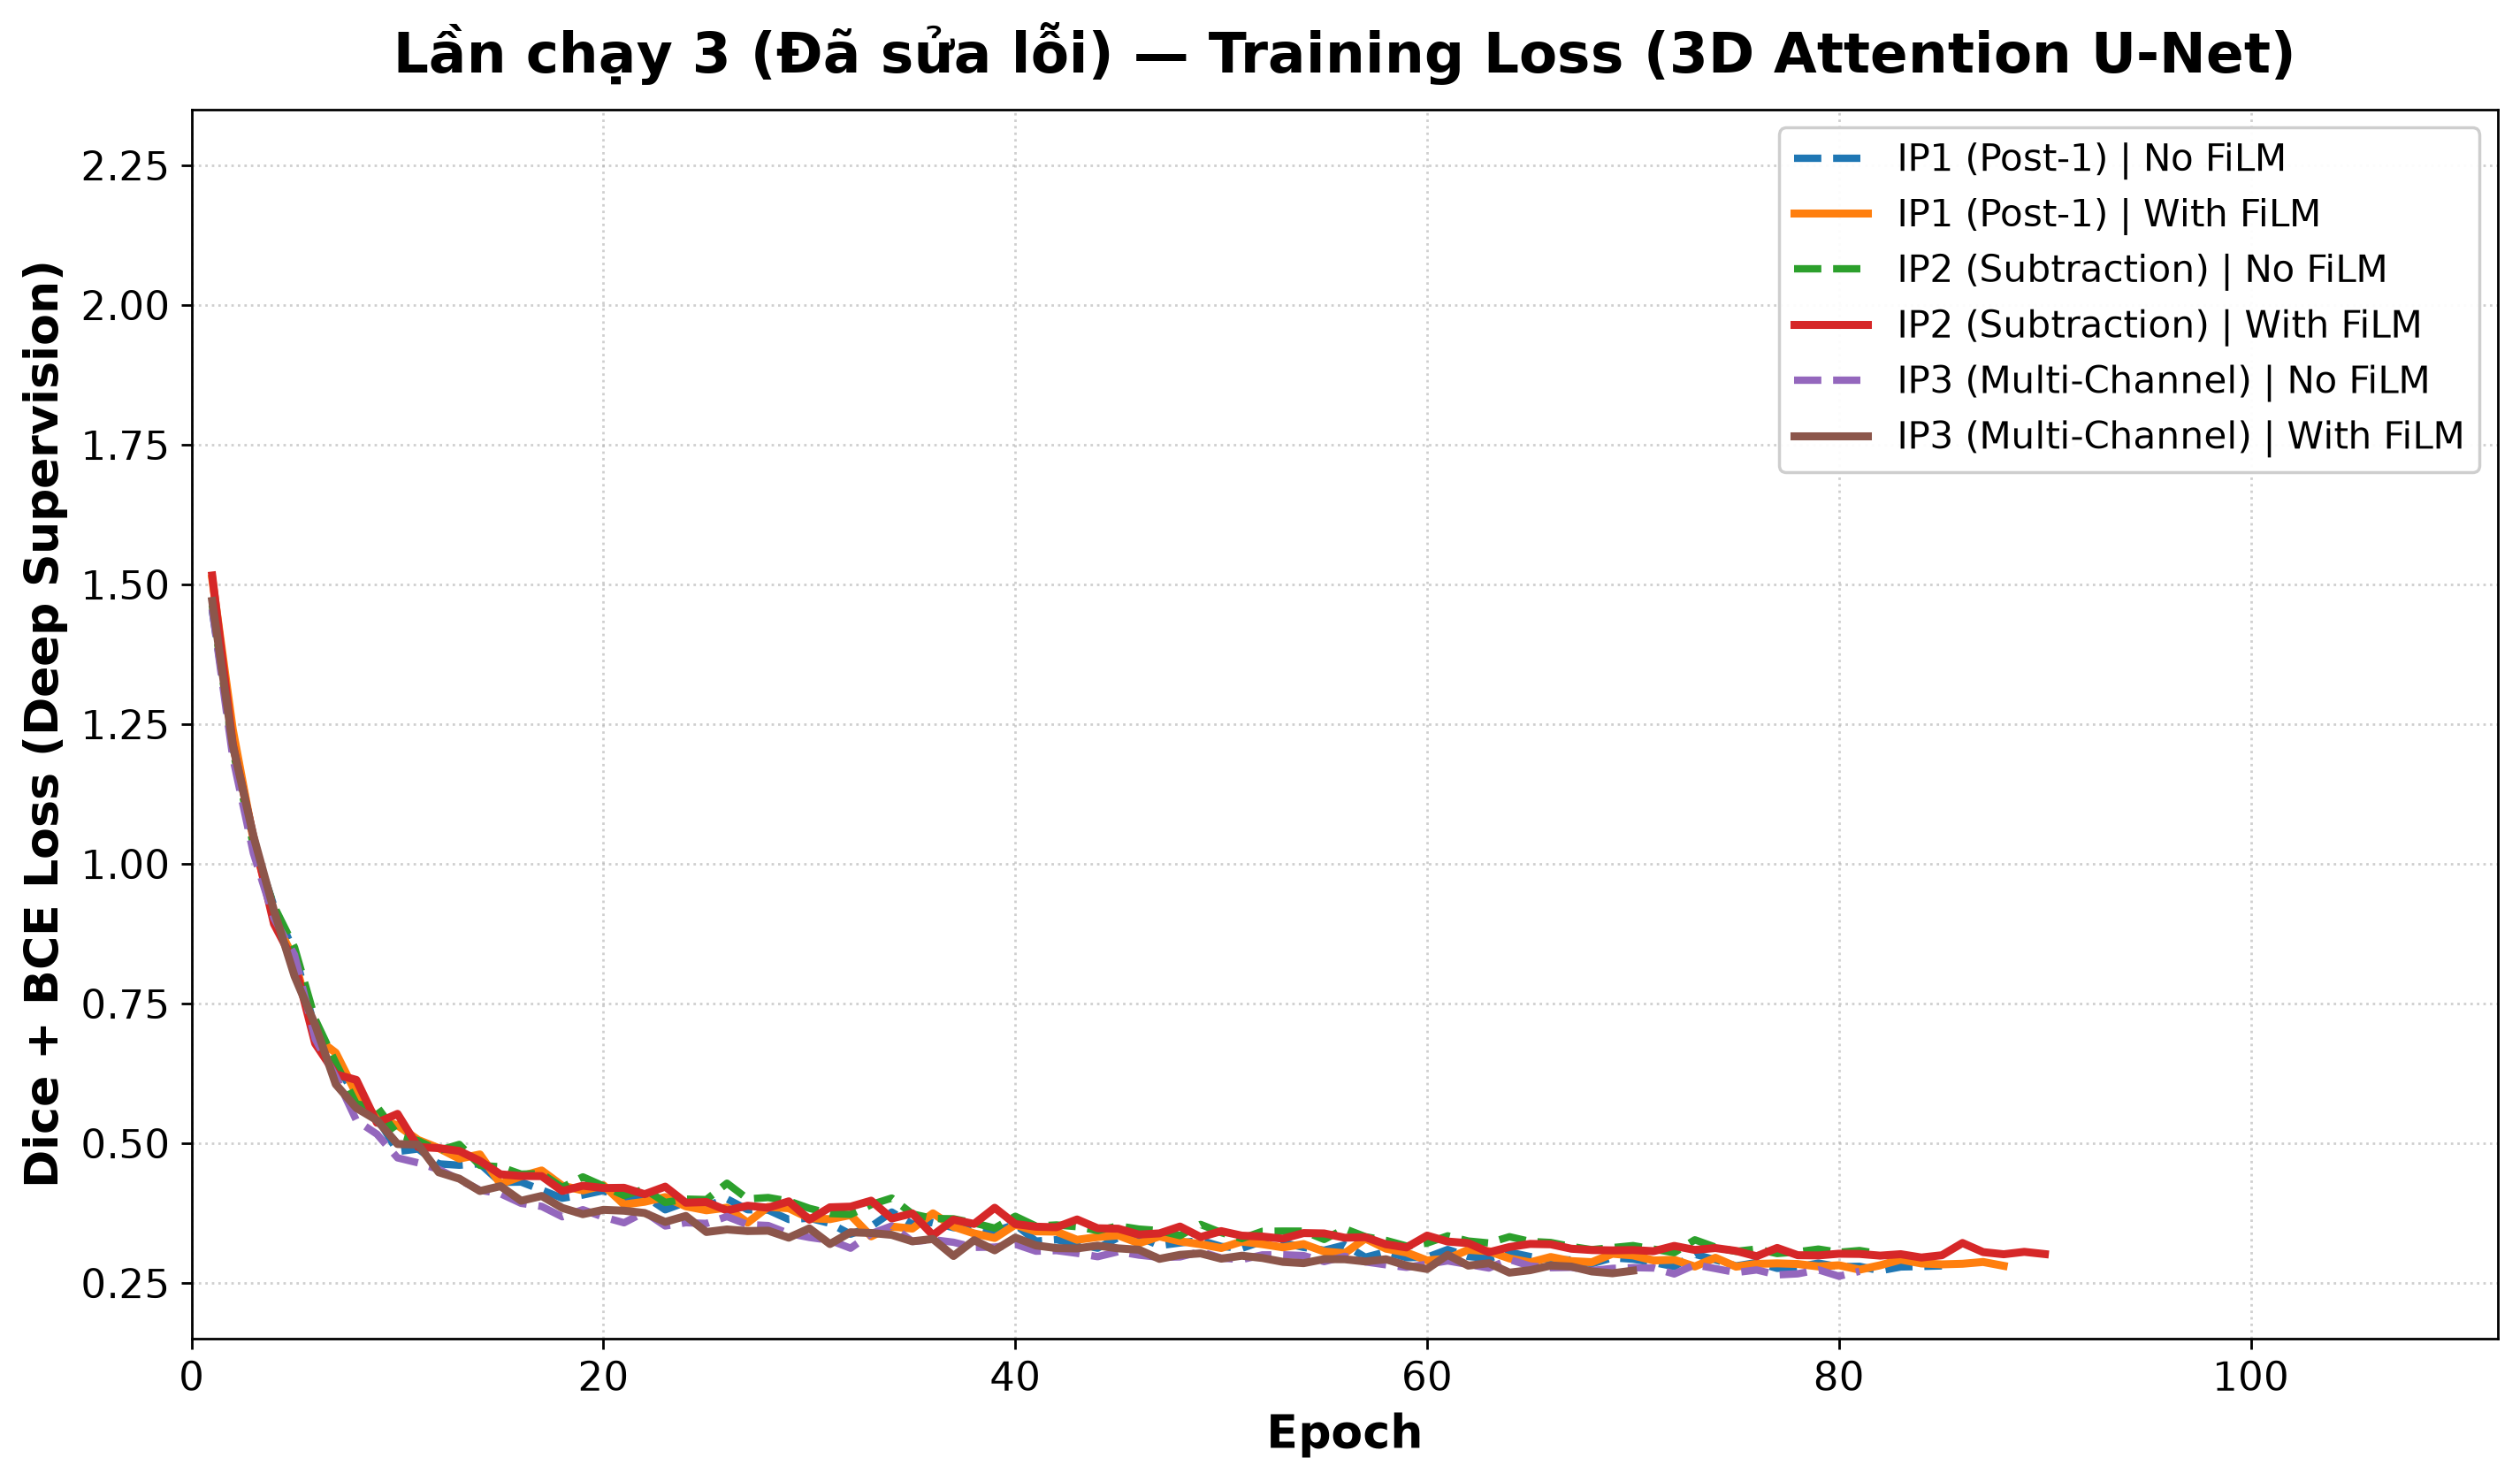

=== BẢNG ĐỐI CHIẾU 12 CON SỐ VALIDATION DICE SCORE (LẦN 1 -> LẦN 3) ===
run_id   ip_mode  use_film  Val_Dice_Lan1  Val_Dice_Lan3 Delta (L3 - L1) Best_Ep (L1 -> L3)
 run07 IP1_post1     False         0.8520         0.8477         -0.0043           72 -> 60
 run08 IP1_post1      True         0.8497         0.8471         -0.0026           84 -> 63
 run09   IP2_sub     False         0.8378         0.8393         +0.0015           76 -> 57
 run10   IP2_sub      True         0.8353         0.8370         +0.0017           61 -> 70
 run11 IP3_multi     False         0.8535         0.8532         -0.0003           72 -> 56
 run12 IP3_multi      True         0.8481         0.8533         +0.0052           32 -> 40


In [3]:
# =========================================================================
# SLIDE 3 FIGURE & 12-NUMBER COMPARISON TABLE (Run 3 vs Run 1)
# =========================================================================
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

WORKSPACE = Path("..") if Path("..").joinpath("outputs_latest").exists() else Path(".")
df3_hist = pd.read_csv(WORKSPACE / "outputs_latest" / "tables" / "tv3_week2_training_histories.csv")
df1_sum = pd.read_csv(WORKSPACE / "outputs_1st" / "tables" / "tv3_week2_ablation_summary.csv")
df3_sum = pd.read_csv(WORKSPACE / "outputs_latest" / "tables" / "tv3_week2_ablation_summary.csv")

RUN_SPECS = [
    ("run07", "IP1 (Post-1) | No FiLM", False, "#1f77b4"),
    ("run08", "IP1 (Post-1) | With FiLM", True, "#ff7f0e"),
    ("run09", "IP2 (Subtraction) | No FiLM", False, "#2ca02c"),
    ("run10", "IP2 (Subtraction) | With FiLM", True, "#d62728"),
    ("run11", "IP3 (Multi-Channel) | No FiLM", False, "#9467bd"),
    ("run12", "IP3 (Multi-Channel) | With FiLM", True, "#8c564b"),
]

fig, ax = plt.subplots(figsize=(11.5, 6.8), dpi=250)

for run_id, label, use_film, color in RUN_SPECS:
    sub = df3_hist[df3_hist["run_id"] == run_id].sort_values("epoch")
    ls = "-" if use_film else "--"
    lw = 2.6 if use_film else 2.4
    ax.plot(sub["epoch"], sub["train_loss"], linestyle=ls, linewidth=lw, color=color, label=label)

ax.set_title("Lần chạy 3 (Đã sửa lỗi) — Training Loss (3D Attention U-Net)", fontsize=18, fontweight="bold", pad=12)
ax.set_xlabel("Epoch", fontsize=15, fontweight="bold")
ax.set_ylabel("Dice + BCE Loss (Deep Supervision)", fontsize=15, fontweight="bold")
# Giữ nguyên scale trục Y (0.15 -> 2.35) giống Slide 1 để đối chiếu trực diện
ax.set_ylim(0.15, 2.35)
ax.set_xlim(0, 112)
ax.tick_params(axis="both", labelsize=13)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right", fontsize=12, frameon=True, framealpha=0.95)

plt.tight_layout()
plt.show()

# Bảng đối chiếu 12 con số Validation Dice Score (Lần 1 -> Lần 3)
comp = pd.DataFrame({
    "run_id": df1_sum["run_id"],
    "ip_mode": df1_sum["ip_mode"],
    "use_film": df1_sum["use_film"],
    "Val_Dice_Lan1": df1_sum["best_val_dice"].round(4),
    "Val_Dice_Lan3": df3_sum["best_val_dice"].round(4),
})
comp["Delta (L3 - L1)"] = (comp["Val_Dice_Lan3"] - comp["Val_Dice_Lan1"]).map(lambda x: f"{x:+.4f}")
comp["Best_Ep (L1 -> L3)"] = df1_sum["best_epoch"].astype(str) + " -> " + df3_sum["best_epoch"].astype(str)

print("=== BẢNG ĐỐI CHIẾU 12 CON SỐ VALIDATION DICE SCORE (LẦN 1 -> LẦN 3) ===")
print(comp.to_string(index=False))